# N1　資料健檢與稼動率（第 2 節）

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RealKazuya/ai-manufacturing-lab/blob/main/notebooks/N1_iot_health.ipynb)

〈AI賦能製造：從工廠數據到AI決策〉課程筆記本。資料全部是教學用虛構（恆準精密工業）。

**用法**：由上往下逐格執行（Shift＋Enter）。要改的參數都在「參數」那一格。

In [1]:
# ── 環境設定（每次開啟先執行這一格）──
import sys, os
IN_COLAB = "google.colab" in sys.modules
LOCAL_DATA = os.path.join("..", "data")
DATA = LOCAL_DATA if os.path.isdir(LOCAL_DATA) else "https://raw.githubusercontent.com/RealKazuya/ai-manufacturing-lab/main/data/"
def path(p):
    return os.path.join(DATA, p) if DATA == LOCAL_DATA else DATA + p
print("資料來源：", "本機" if DATA == LOCAL_DATA else "GitHub", "｜Colab：", IN_COLAB)

資料來源： 本機 ｜Colab： False


In [2]:
import matplotlib, matplotlib.pyplot as plt
if IN_COLAB:   # Colab 沒有中文字型，下載思源黑體（約 16 MB）
    import urllib.request, matplotlib.font_manager as fm
    f = "/tmp/NotoSansTC.otf"
    if not os.path.exists(f):
        urllib.request.urlretrieve("https://github.com/google/fonts/raw/main/ofl/notosanstc/NotoSansTC%5Bwght%5D.ttf", f)
    fm.fontManager.addfont(f); matplotlib.rcParams["font.family"] = fm.FontProperties(fname=f).get_name()
else:
    matplotlib.rcParams["font.family"] = ["Microsoft JhengHei", "sans-serif"]
matplotlib.rcParams["axes.unicode_minus"] = False

## 參數

In [3]:
THRESHOLD = 5      # 主軸負載超過幾 % 算「在加工」（現場改成 30 再跑一次）

## 讀資料

VMC-01～03 在 2026-09-10 的 10 秒資料。欄位：時間、機台、主軸負載 %、轉速、主軸溫度、振動 RMS、加工件數、狀態。

In [4]:
import pandas as pd, numpy as np
df = pd.read_csv(path("iot/vmc_20260910_raw.csv"), parse_dates=["timestamp"])
print(len(df), "列"); df.head()

25830 列


,timestamp,machine,spindle_load_pct,spindle_rpm,spindle_temp,vibration_rms,part_count,state
0,2026-09-10 00:00:00,VMC-01,0.0,0,28.1,0.05,21340,OFF
1,2026-09-10 00:00:10,VMC-01,0.0,0,28.0,0.06,21340,OFF
2,2026-09-10 00:00:20,VMC-01,0.0,0,28.1,0.05,21340,OFF
3,2026-09-10 00:00:30,VMC-01,0.0,0,28.0,0.05,21340,OFF
4,2026-09-10 00:00:40,VMC-01,0.0,0,28.0,0.05,21340,OFF


## 資料健檢：八病逐一檢查

程式只會告訴你「哪裡怪」，是資料壞了還是機台真的停，要人判斷。

In [5]:
findings = []
for m, g in df.groupby("machine"):
    g = g.sort_values("timestamp")
    gap = g.timestamp.diff().dt.total_seconds()
    for i in np.flatnonzero(gap > 10):
        findings.append((m, "遺漏", "%s～%s 沒有資料" % (g.timestamp.iloc[i-1].strftime("%H:%M"), g.timestamp.iloc[i].strftime("%H:%M"))))
    dup = g.timestamp.duplicated().sum()
    if dup: findings.append((m, "重複", "%d 筆時間重複" % dup))
    spike = g[g.spindle_load_pct > 150]
    for _, r in spike.iterrows():
        findings.append((m, "突波", "%s 主軸負載 %.0f%%" % (r.timestamp.strftime("%H:%M:%S"), r.spindle_load_pct)))
    hot = g[g.spindle_temp > 60]
    if len(hot): findings.append((m, "單位不一？", "%s～%s 溫度 %.0f 左右（像是 ℉）" % (hot.timestamp.min().strftime("%H:%M"), hot.timestamp.max().strftime("%H:%M"), hot.spindle_temp.median())))
    run = g[g.state == "RUN"]
    same = (run.vibration_rms.diff() == 0).astype(int)
    blk = same.groupby((same == 0).cumsum()).transform("sum")
    if blk.max() >= 30:
        s = run[blk >= 30]
        findings.append((m, "凍結值", "%s～%s 振動都是 %.2f" % (s.timestamp.min().strftime("%H:%M"), s.timestamp.max().strftime("%H:%M"), s.vibration_rms.iloc[0])))
    dec = g[g.part_count.diff() < 0]
    for _, r in dec.iterrows():
        findings.append((m, "計數器歸零？", "%s 件數由大變 0" % r.timestamp.strftime("%H:%M:%S")))
    first = g[g.state == "RUN"].timestamp.min()
    findings.append((m, "上班時間", "第一次加工 %s（其他台都是 08:00 左右嗎？）" % first.strftime("%H:%M")))
    idle = g[(g.state == "IDLE") & (g.timestamp.dt.hour.between(0, 23))]
pd.DataFrame(findings, columns=["機台", "可能的問題", "說明"])

,機台,可能的問題,說明
0,VMC-01,遺漏,15:09～15:25 沒有資料
1,VMC-01,單位不一？,13:20～14:04 溫度 94 左右（像是 ℉）
2,VMC-01,上班時間,第一次加工 08:01（其他台都是 08:00 左右嗎？）
3,VMC-02,凍結值,10:40～11:19 振動都是 2.29
4,VMC-02,計數器歸零？,16:02:40 件數由大變 0
5,VMC-02,上班時間,第一次加工 08:01（其他台都是 08:00 左右嗎？）
6,VMC-03,突波,09:47:00 主軸負載 980%
7,VMC-03,上班時間,第一次加工 00:01（其他台都是 08:00 左右嗎？）


## 看圖：三台機一天的主軸負載

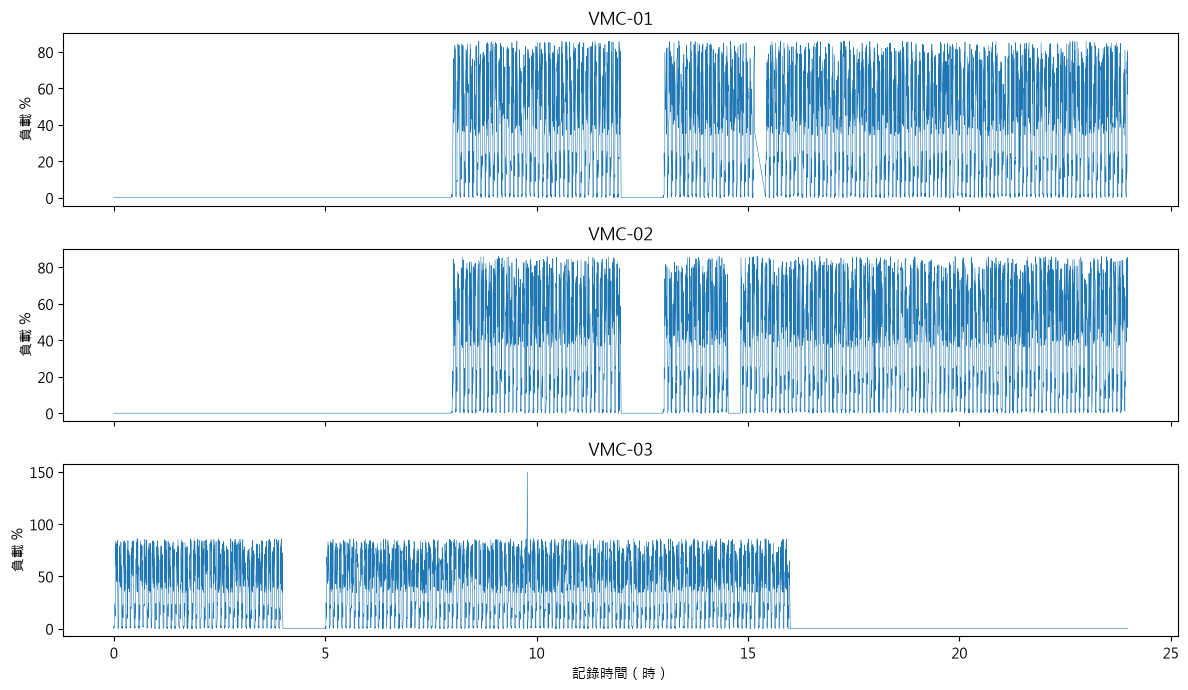

In [6]:
fig, ax = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for a, (m, g) in zip(ax, df.groupby("machine")):
    a.plot(g.timestamp.dt.hour + g.timestamp.dt.minute / 60, g.spindle_load_pct.clip(upper=150), lw=0.4)
    a.set_title(m); a.set_ylabel("負載 %")
ax[-1].set_xlabel("記錄時間（時）"); plt.tight_layout(); plt.show()

## 稼動率：定義一改，KPI 就變

計畫時間：08:00～24:00 扣掉午休。主軸負載超過 `THRESHOLD` 算在加工。

In [7]:
def utilization(g, thr):
    h = g.timestamp.dt.hour + g.timestamp.dt.minute / 60
    plan = (h >= 8) & ~((h >= 12) & (h < 13))
    return (g.loc[plan, "spindle_load_pct"] > thr).mean()
v2 = df[df.machine == "VMC-02"]
print("VMC-02 稼動率（負載 > %d%% 算加工）：%.1f%%" % (THRESHOLD, utilization(v2, THRESHOLD) * 100))
for t in (5, 30):
    print("  門檻 %2d%% → %.1f%%" % (t, utilization(v2, t) * 100))

VMC-02 稼動率（負載 > 5% 算加工）：78.0%
  門檻  5% → 78.0%
  門檻 30% → 61.5%
